# Shor's code, step by step: the bit-flip code, and the nine-qubit code

> **In short.**
> * **The bit-flip code in ZX.** A ZX derivation draws the three-qubit bit-flip code: its encoder, a parity check measured with a helper qubit and what it measures, the code's checks applied to the encoder, and a phase flip that is a logical error. Each is a small program here, levelled up one rewrite per level (`level_up(..., rewrite=...)`); every level is checked to be the same map as the circuit, in every run (`equal_for_all_assignments`).
> * **Shor's code.** The same rewrites turn Shor's encoder into the encoder of the phase-flip code (a Z-spider joined by Hadamard edges to three) followed by three encoders of the bit-flip code. A phase flip now stops at the spider of its block, and an $X$ check notices it.
> * **The rewrites.** `'copy and fuse'`: states copied through spiders of the other colour, spiders with one leg fused into their neighbour. `'copy results'`: the same, also for a state such as $|a\rangle$ whose phase $a\pi$ is a bit. `'spider_simp'` (PyZX): neighbouring spiders of one colour fused. `'remove identities'`: spiders with two legs and no phase removed, and the spiders they joined fused.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders, a blue edge is a Hadamard. A red dot with one leg on the left is $|0\rangle$, on the right $\langle 0|$; a phase `a` is $a\pi$.
> * The physical protocol, its questions, errors and circuit distance: [ShorCode.ipynb](ShorCode.ipynb).

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, Z, Measurement, PostSelect
from zxqec.qprogram import QProgram, ParityControlled
from zxqec.gpf import equal_for_all_assignments, reduce_gpf

## The encoder of the bit-flip code

Qubit 0 holds the input, qubits 1 and 2 start in $|0\rangle$, and two CNOTs copy qubit 0 onto them. The circuit, then two levels: `'copy and fuse'`, `'remove identities'`.

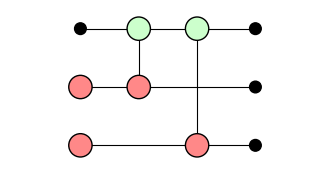

level 1, the same map as the circuit: True


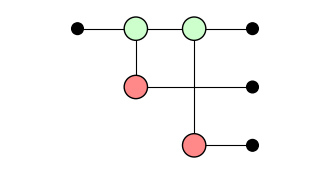

level 2, the same map as the circuit: True


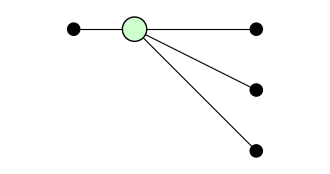

In [2]:
encoder = QProgram(3, initial_states={1: '0', 2: '0'})
c = Circuit(3)
for gate in [CNOT(0, 1), CNOT(0, 2)]:
    c.add_gate(gate)
encoder.add_circuit(c, name='encoder')
circuit = encoder.quantum_graph()
levels = [encoder.level_up(0, 0, 0, 'encoder', rewrite='copy and fuse')]
levels.append(encoder.level_up(levels[-1], 0, 0, 'encoder', rewrite='remove identities'))
display(zx.draw_matplotlib(circuit, figsize=(4, 2)))
for level in levels:
    picture = encoder.reduced_level(level).graph
    print("level {}, the same map as the circuit: {}".format(level, equal_for_all_assignments(circuit, picture)))
    display(zx.draw_matplotlib(picture, figsize=(4, 2)))

Each CNOT is a Z-spider on its control joined to an X-spider on its target. `'copy and fuse'` fuses each $|0\rangle$ into the X-spider next to it, which is left with two legs: an identity where the wire turns. `'remove identities'` removes them and fuses the two Z-spiders: one Z-spider, the input copied onto three outputs.

## Measuring the parity $Z Z$

The check $Z_0 Z_1$, on three wires as the derivation draws it, measured with a helper (qubit 3) in $|0\rangle$ and post-selected on the result 0 (`PostSelect`, the effect $\langle 0|$). Three levels: `'copy and fuse'`, `'spider_simp'`, `'remove identities'`.

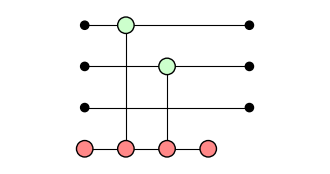

level 1, the same map as the circuit: True


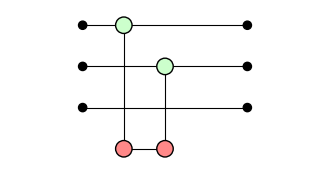

level 2, the same map as the circuit: True


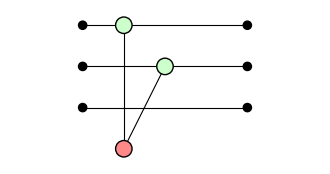

level 3, the same map as the circuit: True


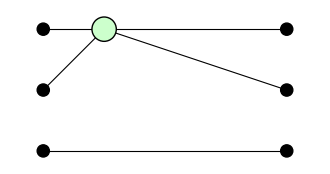

In [3]:
check = QProgram(4, initial_states={3: '0'})
c = Circuit(4)
for gate in [CNOT(0, 3), CNOT(1, 3), PostSelect(3, '0')]:
    c.add_gate(gate)
check.add_circuit(c, name='Z Z')
circuit = check.quantum_graph()
levels = [check.level_up(0, 0, 0, 'Z Z', rewrite='copy and fuse')]
for rewrite in ('spider_simp', 'remove identities'):
    levels.append(check.level_up(levels[-1], 0, 0, 'Z Z', rewrite=rewrite))
display(zx.draw_matplotlib(circuit, figsize=(4, 2)))
for level in levels:
    picture = check.reduced_level(level).graph
    print("level {}, the same map as the circuit: {}".format(level, equal_for_all_assignments(circuit, picture)))
    display(zx.draw_matplotlib(picture, figsize=(4, 2)))

The circuit is already the derivation's second picture: Z-spiders on qubits 0 and 1, X-spiders on the helper, with $|0\rangle$ and $\langle 0|$ at its ends. `'copy and fuse'` fuses $|0\rangle$ and $\langle 0|$ into the X-spiders next to them, and `'spider_simp'` fuses the two X-spiders: one X-spider joined to the two Z-spiders, the derivation's last pictures. The derivation stops there. `'remove identities'` goes one step further: that X-spider has two legs, an identity, and the two Z-spiders fuse into one, on both wires: $|00\rangle\langle 00| + |11\rangle\langle 11|$, the projector onto even parity.

## What the check measures

The derivation puts basis states $|a\rangle$ and $|b\rangle$ (X-spiders with phases $a\pi$ and $b\pi$) into the check. Here they are $|0\rangle$ followed by an $X$ controlled by a bit $a$ (and $b$), `ParityControlled('X', 0, ['a'])`. Two programs: the check post-selected on 0, as in the derivation, and measured, with result `c[0]`. Levels of the first: `'spider_simp'` (the parity check with $|a\rangle$, $|b\rangle$ on its inputs), then `'copy results'`, which copies $a\pi$ and $b\pi$ through the Z-spiders and fuses what meets.

level 1, the same map as the circuit: True


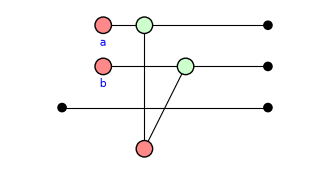

level 2, the same map as the circuit: True


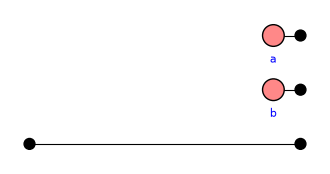

the number in front of the last picture: sqrt(2)^-2(1+exp((a + b)ipi))
measured instead: every run has ['c[0] + a + b = 0']


In [4]:
programs = {}
for name, last in (('post-selected', PostSelect(3, '0')), ('measured', Measurement(3, 0))):
    programs[name] = QProgram(4, bits=1, initial_states={0: '0', 1: '0', 3: '0'})
    for stage, gates in (('|a>, |b>', [ParityControlled('X', 0, ['a']), ParityControlled('X', 1, ['b'])]),
                         ('Z Z', [CNOT(0, 3), CNOT(1, 3), last])):
        c = Circuit(4, bit_amount=1)
        for gate in gates:
            c.add_gate(gate)
        programs[name].add_circuit(c, name=stage)
check = programs['post-selected']
circuit = check.quantum_graph()
levels = [check.level_up(0, 0, 1, 'all', rewrite='spider_simp')]
levels.append(check.level_up(levels[-1], 0, 0, 'all', rewrite='copy results'))
for level in levels:
    picture = check.reduced_level(level).graph
    print("level {}, the same map as the circuit: {}".format(level, equal_for_all_assignments(circuit, picture)))
    display(zx.draw_matplotlib(picture, figsize=(4, 2)))
print("the number in front of the last picture:", picture.scalar)
print("measured instead: every run has", [str(x) + " = 0" for x in reduce_gpf(programs['measured'].quantum_graph()).constraints])

The last picture is $|a\rangle$ and $|b\rangle$ on the outputs, the helper gone, times the number printed, $(1 + e^{i\pi(a+b)})/2$: 1 when $a \oplus b = 0$ and 0 otherwise. The derivation has two pictures in between ($a\pi$ and $b\pi$ copied, then fused into $(a+b)\pi$); `'copy results'` does them in one level. Measured instead of post-selected, the result is $a \oplus b$ in every run: `c[0] + a + b` is 0.

## A check applied to the encoder

$Z Z I$ after the encoder: $Z$ on qubits 0 and 1. Three levels: `'copy and fuse'`, `'remove identities'`, `'spider_simp'`.

level 1, the same map as the circuit: True


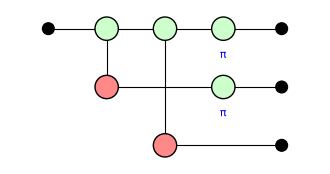

level 2, the same map as the circuit: True


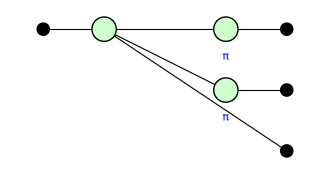

level 3, the same map as the circuit: True


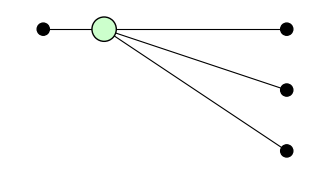

In [5]:
encoded = QProgram(3, initial_states={1: '0', 2: '0'})
for name, gates in (('encoder', [CNOT(0, 1), CNOT(0, 2)]), ('Z Z I', [Z(0), Z(1)])):
    c = Circuit(3)
    for gate in gates:
        c.add_gate(gate)
    encoded.add_circuit(c, name=name)
circuit = encoded.quantum_graph()
levels = [encoded.level_up(0, 0, 1, 'all', rewrite='copy and fuse')]
for rewrite in ('remove identities', 'spider_simp'):
    levels.append(encoded.level_up(levels[-1], 0, 0, 'all', rewrite=rewrite))
for level in levels:
    picture = encoded.reduced_level(level).graph
    print("level {}, the same map as the circuit: {}".format(level, equal_for_all_assignments(circuit, picture)))
    display(zx.draw_matplotlib(picture, figsize=(4, 2)))

`'remove identities'` gives the encoder's Z-spider with a $\pi$ on two of its outputs. `'spider_simp'` fuses them in: $2\pi$, which is 0, so the encoder again. A check does nothing to the states of the code.

## A check's projector applied to the encoder

The projector of $I Z Z$ (the parity check, on qubits 1 and 2, with a helper on qubit 3) after the encoder. Two levels: `'copy and fuse'`, `'remove identities'`.

level 1, the same map as the circuit: True


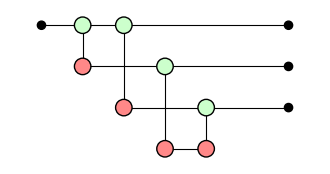

level 2, the same map as the circuit: True


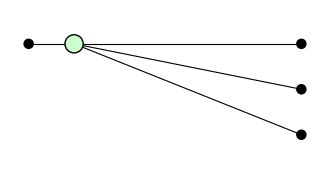

In [6]:
projected = QProgram(4, initial_states={1: '0', 2: '0', 3: '0'})
for name, gates in (('encoder', [CNOT(0, 1), CNOT(0, 2)]), ('I Z Z', [CNOT(1, 3), CNOT(2, 3), PostSelect(3, '0')])):
    c = Circuit(4)
    for gate in gates:
        c.add_gate(gate)
    projected.add_circuit(c, name=name)
circuit = projected.quantum_graph()
levels = [projected.level_up(0, 0, 1, 'all', rewrite='copy and fuse')]
levels.append(projected.level_up(levels[-1], 0, 0, 'all', rewrite='remove identities'))
for level in levels:
    picture = projected.reduced_level(level).graph
    print("level {}, the same map as the circuit: {}".format(level, equal_for_all_assignments(circuit, picture)))
    display(zx.draw_matplotlib(picture, figsize=(4, 2)))

`'remove identities'` does both steps of the derivation, the identity removed and the spiders fused, in one level: the encoder again. The projector does nothing to the states of the code.

## A phase flip in the bit-flip code

$Z$ on qubit 2 after the encoder. Three levels: `'copy and fuse'`, `'remove identities'`, `'spider_simp'`.

level 1, the same map as the circuit: True


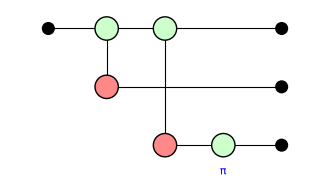

level 2, the same map as the circuit: True


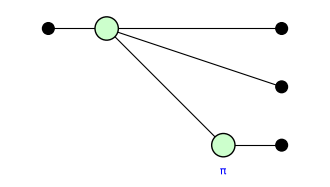

level 3, the same map as the circuit: True


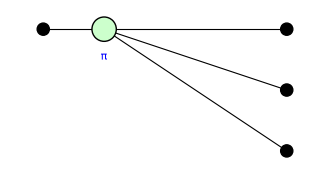

In [7]:
flipped = QProgram(3, initial_states={1: '0', 2: '0'})
for name, gates in (('encoder', [CNOT(0, 1), CNOT(0, 2)]), ('Z on qubit 2', [Z(2)])):
    c = Circuit(3)
    for gate in gates:
        c.add_gate(gate)
    flipped.add_circuit(c, name=name)
circuit = flipped.quantum_graph()
levels = [flipped.level_up(0, 0, 1, 'all', rewrite='copy and fuse')]
for rewrite in ('remove identities', 'spider_simp'):
    levels.append(flipped.level_up(levels[-1], 0, 0, 'all', rewrite=rewrite))
for level in levels:
    picture = flipped.reduced_level(level).graph
    print("level {}, the same map as the circuit: {}".format(level, equal_for_all_assignments(circuit, picture)))
    display(zx.draw_matplotlib(picture, figsize=(4, 2)))

`'remove identities'` gives the encoder's Z-spider with a $\pi$ on one output, `'spider_simp'` the $\pi$ fused into the encoder's Z-spider. Fusion read backwards puts that $\pi$ on the input wire, before the encoder (not drawn here): a $Z$ on the logical qubit. A phase flip on any one qubit is a logical $Z$, which no $Z Z$ check can notice.

## Shor's encoder

Shor's encoder, as in [ShorCode.ipynb](ShorCode.ipynb): CNOTs from qubit 0 to 3 and 6, $H$ on 0, 3 and 6, then each of 0, 3, 6 copied onto the next two qubits. Two levels: `'copy and fuse'`, `'remove identities'`.

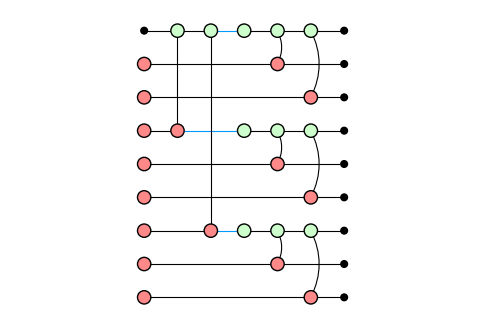

level 1, the same map as the circuit: True


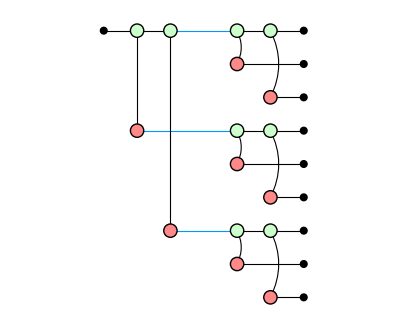

level 2, the same map as the circuit: True


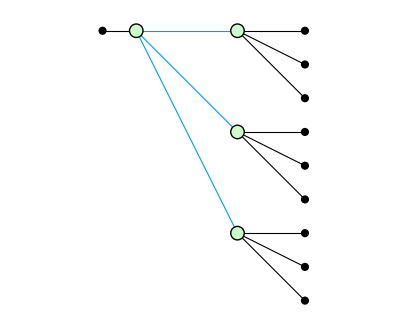

In [8]:
ENCODER = [CNOT(0, 3), CNOT(0, 6), HAD(0), HAD(3), HAD(6)] + [CNOT(b, b + k) for b in (0, 3, 6) for k in (1, 2)]
shor = QProgram(9, initial_states={q: '0' for q in range(1, 9)})
c = Circuit(9)
for gate in ENCODER:
    c.add_gate(gate)
shor.add_circuit(c, name='encoder')
circuit = shor.quantum_graph()
levels = [shor.level_up(0, 0, 0, 'encoder', rewrite='copy and fuse')]
levels.append(shor.level_up(levels[-1], 0, 0, 'encoder', rewrite='remove identities'))
display(zx.draw_matplotlib(circuit, figsize=(6, 4)))
for level in levels:
    picture = shor.reduced_level(level).graph
    print("level {}, the same map as the circuit: {}".format(level, equal_for_all_assignments(circuit, picture)))
    display(zx.draw_matplotlib(picture, figsize=(5, 4)))

The last level is the two codes, one inside the other. The input's Z-spider, joined by Hadamard edges (blue) to three Z-spiders, is the phase-flip code: the bit-flip encoder with an $H$ on each output, $|0\rangle \mapsto |{+}{+}{+}\rangle$. Each of the three Z-spiders, copied onto three qubits, is the encoder of the bit-flip code.

## A phase flip in Shor's code

$Z$ on qubit 4 after Shor's encoder, with `'spider_simp'` as a third level (the last level drawn); then a second program, the same error followed by the $X$ check on qubits 0 to 5 (a helper on qubit 9, measured).

level 1, the same map as the circuit: True


level 2, the same map as the circuit: True
level 3, the same map as the circuit: True


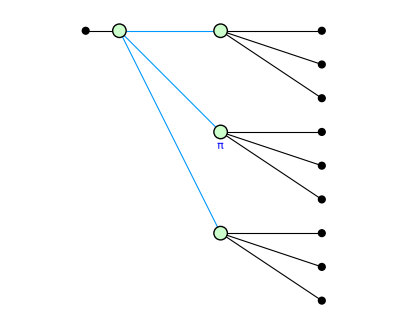

with the X check after it, every run has ['c[0] + 1 = 0']


In [9]:
flipped = QProgram(9, initial_states={q: '0' for q in range(1, 9)})
for name, gates in (('encoder', ENCODER), ('Z on qubit 4', [Z(4)])):
    c = Circuit(9)
    for gate in gates:
        c.add_gate(gate)
    flipped.add_circuit(c, name=name)
circuit = flipped.quantum_graph()
levels = [flipped.level_up(0, 0, 1, 'all', rewrite='copy and fuse')]
for rewrite in ('remove identities', 'spider_simp'):
    levels.append(flipped.level_up(levels[-1], 0, 0, 'all', rewrite=rewrite))
for level in levels:
    print("level {}, the same map as the circuit: {}".format(level, equal_for_all_assignments(circuit, flipped.reduced_level(level).graph)))
display(zx.draw_matplotlib(flipped.reduced_level(levels[-1]).graph, figsize=(5, 4)))
caught = QProgram(10, bits=1, initial_states={q: '0' for q in range(1, 10)})
for name, gates in (('encoder', ENCODER), ('Z on qubit 4', [Z(4)]),
                    ('X check', [HAD(9)] + [CNOT(9, q) for q in (0, 3, 1, 4, 2, 5)] + [HAD(9), Measurement(9, 0)])):
    c = Circuit(10, bit_amount=1)
    for gate in gates:
        c.add_gate(gate)
    caught.add_circuit(c, name=name)
print("with the X check after it, every run has", [str(x) + " = 0" for x in reduce_gpf(caught.quantum_graph()).constraints])

The $\pi$ fuses into the Z-spider of its block, as in the bit-flip code, but stops there: fusion needs a plain edge between spiders of one colour, and between that spider and the input's there is a Hadamard edge. That spider sits on the block's qubit of the phase-flip code (the wire after the Hadamard), so the $\pi$ is a $Z$ on one qubit of the phase-flip code, which that code notices: its checks, $X X$ on two of its qubits, are the $X$ checks on six physical qubits. Measured after the error, the result of the $X$ check is 1 in every run (`c[0] + 1` is 0).

## How this differs from the derivation

* The circuits have no measurement results, swaps or resets to redraw, so `'standard notation'` is not needed; PyZX's picture of the circuit is already the standard notation.
* Some levels do two of the derivation's steps at once: `'remove identities'` for the parity check and for the projector on the encoder, `'copy results'` for what the check measures.
* The last picture of the phase flip, the $\pi$ moved before the encoder, is not drawn: it is fusion read backwards.
* Shor's code is not in the derivation; its encoder here is drawn with the same rewrites.